In [9]:
import json
import os

RESULTS_DIR = "/home/as5606/projects/Super_LlaVA_Med/model_score/combined_results"

files = {
    "X-ray":           "xray_val_results.json",
    "CT":              "ct_val_results.json",
    "MRI":             "mri_val_results.json",
    "Histology":       "histology_val_results.json",
    "Gross Pathology": "pathology_val_results.json",
}

REFUSAL = "I cannot answer."

print(f"{'Domain':<20} {'WA (%)':>8} {'RA (%)':>8}")
print("-" * 40)

for domain, fname in files.items():
    records = json.load(open(os.path.join(RESULTS_DIR, fname)))

    std = [r for r in records if r["type"] == "standard"]
    upd = [r for r in records if r["type"] == "upd"]

    # WA: model refused on answerable question (wrong)
    wa = sum(1 for r in std if r["model_answer"] == REFUSAL)
    # RA: model refused on unanswerable question (correct)
    ra = sum(1 for r in upd if r["model_answer"] == REFUSAL)

    wa_pct = wa / len(std) * 100
    ra_pct = ra / len(upd) * 100

    print(f"{domain:<20} {wa_pct:>7.1f}% {ra_pct:>7.1f}%")


Domain                 WA (%)   RA (%)
----------------------------------------
X-ray                   19.2%    87.5%
CT                      13.2%    93.3%
MRI                     12.0%    93.9%
Histology               17.6%    92.9%
Gross Pathology          7.1%    69.3%


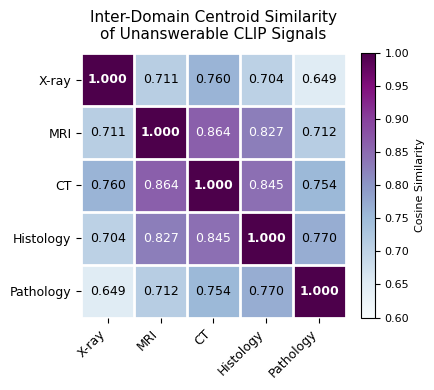

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

OUT_DIR = "/home/as5606/projects/Super_LlaVA_Med/paper_graphs"

upd_signals = np.load(f"{OUT_DIR}/clip_signals.npy")
upd_labels  = np.load(f"{OUT_DIR}/clip_labels.npy")

DOMAINS = ["X-ray", "MRI", "CT", "Histology", "Pathology"]

centroids = {}
for domain in DOMAINS:
    mask = upd_labels == domain
    centroids[domain] = upd_signals[mask].mean(axis=0)

centroid_matrix = np.stack([centroids[d] for d in DOMAINS])
sim_matrix = cosine_similarity(centroid_matrix)

fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(sim_matrix, cmap="BuPu", vmin=0.6, vmax=1.0)

for i in range(len(DOMAINS)):
    for j in range(len(DOMAINS)):
        val = sim_matrix[i, j]
        color = "white" if val > 0.80 else "black"
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                fontsize=9, color=color,
                fontweight="bold" if i == j else "normal")

ax.set_xticks(range(len(DOMAINS)))
ax.set_yticks(range(len(DOMAINS)))
ax.set_xticklabels(DOMAINS, fontsize=9, rotation=45, ha="right")
ax.set_yticklabels(DOMAINS, fontsize=9)

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=8)
cbar.set_label("Cosine Similarity", fontsize=8)

ax.set_title("Inter-Domain Centroid Similarity\nof Unanswerable CLIP Signals",
             fontsize=11, pad=10)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(len(DOMAINS)+1)-0.5, minor=True)
ax.set_yticks(np.arange(len(DOMAINS)+1)-0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/domain_centroid_similarity.pdf", bbox_inches="tight", dpi=300)
plt.show()
